# MSCS 634 – Project Deliverable 1
## Data Collection, Cleaning, and Exploration
**Project:** Advanced Data Mining for Data-Driven Insights and Predictive Modeling
**Student:** Ruchitha Musku
**Dataset:** IBM Telco Customer Churn (7,043 customers × 21 attributes)

---
### Contents
1. Dataset selection and justification
2. Loading and inspecting the data
3. Data cleaning: missing values, inconsistent data, duplicates, noisy data
4. Exploratory data analysis (EDA)
5. Key insights and how they guide the next deliverables

## 1. Dataset Selection and Justification

**Source:** IBM Telco Customer Churn sample dataset, published by IBM and widely mirrored on Kaggle
(`blastchar/telco-customer-churn`). The CSV used here comes from IBM's public GitHub repository
(`IBM/telco-customer-churn-on-icp4d`) and is saved in this repository as `data/Telco-Customer-Churn.csv`.

**What it contains:** Each row is one customer of a fictional telecommunications company in California.
There are 21 columns in four groups:

| Group | Attributes |
|---|---|
| Identifier | `customerID` |
| Demographics | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Account information | `tenure` (months), `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` |
| Subscribed services | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Target | `Churn` (whether the customer left in the last month) |

**Why it suits this project:**
- **Size:** 7,043 records and 20 usable attributes, well above the 500-record and 8–10-attribute minimums.
- **Mix of data types:** numeric columns (`tenure`, `MonthlyCharges`, `TotalCharges`) and many categorical columns, so it exercises a range of preprocessing techniques.
- **Real cleaning work:** `TotalCharges` is stored as text with blank values, and categorical coding is inconsistent, so it needs genuine cleaning.
- **Fits every later deliverable:**
  - *Regression (Deliverable 2):* predict `MonthlyCharges` or `TotalCharges` from services and tenure.
  - *Classification (Deliverable 3):* predict `Churn` (Yes/No).
  - *Clustering (Deliverable 3):* segment customers by tenure, spending and service bundles.
  - *Association rules (Deliverable 3):* the Yes/No service columns work naturally as "market basket" items.
- **Business relevance:** keeping an existing customer costs much less than acquiring a new one, so understanding churn has direct practical value.

## 2. Load the Dataset and Inspect Its Structure

In [1]:
# --- Import libraries -------------------------------------------------------
import numpy as np                 # numerical operations
import pandas as pd                # data loading and manipulation
import matplotlib.pyplot as plt    # base plotting library
import seaborn as sns              # statistical visualisation built on matplotlib
import warnings
warnings.filterwarnings("ignore")  # keep the notebook output readable

# Consistent, readable styling for every figure
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

# Show all columns when displaying DataFrames
pd.set_option("display.max_columns", None)

# Folder where figures are also saved as PNG files (referenced from README.md)
import os
os.makedirs("figures", exist_ok=True)

In [2]:
# --- Load the raw CSV file ---------------------------------------------------
# The file is kept in the repository's data/ folder so the notebook runs as-is.
DATA_PATH = "data/Telco-Customer-Churn.csv"
raw_df = pd.read_csv(DATA_PATH)

# Work on a copy so the raw data stays untouched for comparison
df = raw_df.copy()

print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset shape: 7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# --- Structure: column names, data types and non-null counts -----------------
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# --- Number of unique values per column --------------------------------------
# This shows which columns are categorical (few unique values) and which are continuous.
df.nunique().sort_values().to_frame("unique_values").T

,gender,SeniorCitizen,Partner,Dependents,PhoneService,PaperlessBilling,Churn,MultipleLines,TechSupport,StreamingTV,OnlineBackup,DeviceProtection,StreamingMovies,Contract,OnlineSecurity,InternetService,PaymentMethod,tenure,MonthlyCharges,TotalCharges,customerID
unique_values,2,2,2,2,2,2,2,3,3,3,3,3,3,3,3,3,4,73,1585,6531,7043


In [5]:
# --- Summary statistics for the numeric columns ------------------------------
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


**Observations from the first inspection**
- 7,043 rows and 21 columns. `info()` reports no nulls, but that is misleading (see below).
- `TotalCharges` should be numeric (a dollar amount) but was loaded as **text**, which suggests non-numeric entries hidden in the column.
- `SeniorCitizen` is coded as **0/1**, while every other yes/no column uses the strings **"Yes"/"No"**: an inconsistency to fix.
- `customerID` is a unique identifier with no predictive value; it will be used to check for duplicates and then dropped from the analysis set.

## 3. Data Cleaning

### 3.1 Handling missing values

In [6]:
# --- Look for hidden missing values ------------------------------------------
# Standard nulls (NaN) per column
print("Standard NaN values per column:", int(df.isnull().sum().sum()))

# Blank / whitespace-only strings are a common way missing data hides in CSV files
text_cols = df.select_dtypes(include=["object", "string"]).columns
blank_counts = {c: int(df[c].astype(str).str.strip().eq("").sum()) for c in text_cols}
blank_counts = {c: n for c, n in blank_counts.items() if n > 0}
print("Blank strings per column:", blank_counts)

Standard NaN values per column: 0
Blank strings per column: {'TotalCharges': 11}


In [7]:
# --- Convert TotalCharges to numeric -----------------------------------------
# errors="coerce" turns the blank strings into NaN so they can be counted and handled.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
missing_mask = df["TotalCharges"].isna()
print(f"Missing TotalCharges after conversion: {missing_mask.sum()} "
      f"({missing_mask.mean():.2%} of rows)")

# Inspect the affected rows to understand WHY the value is missing
df.loc[missing_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

Missing TotalCharges after conversion: 11 (0.16% of rows)


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,No
753,3115-CZMZD,0,20.25,NaN,Two year,No
936,5709-LVOEQ,0,80.85,NaN,Two year,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No
5218,2923-ARZLG,0,19.70,NaN,One year,No
6670,4075-WKNIU,0,73.35,NaN,Two year,No


**Decision: impute `TotalCharges` with 0 instead of dropping rows or using the mean/median.**

Every one of the 11 customers with a blank `TotalCharges` has `tenure = 0`, meaning they have just signed up and
have **not been billed yet**. The value is missing for a structural reason, not at random, so the
logically correct total is **$0**. Mean or median imputation (about $2,280 / $1,400) would invent charges these customers never
paid, and dropping them would discard valid new customers. With only 11 rows (0.16%) the choice barely affects the statistics, but
domain-based imputation is the most defensible.

In [8]:
# --- Impute: customers with zero tenure have accumulated zero charges ----------
assert (df.loc[missing_mask, "tenure"] == 0).all(), "Unexpected: missing values with tenure > 0"
df.loc[missing_mask, "TotalCharges"] = 0.0

print("Remaining missing values in the whole dataset:", int(df.isnull().sum().sum()))
print("TotalCharges dtype is now:", df["TotalCharges"].dtype)

Remaining missing values in the whole dataset: 0
TotalCharges dtype is now: float64


### 3.2 Removing duplicates

In [9]:
# --- Check for duplicate records ---------------------------------------------
# 1) Exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# 2) Duplicate customer IDs (the same customer recorded twice)
print("Duplicate customerID values:", df["customerID"].duplicated().sum())

# 3) Duplicate rows once the ID is ignored: different customers with identical attributes
dup_wo_id = df.drop(columns="customerID").duplicated().sum()
print("Rows identical on all attributes except customerID:", dup_wo_id)

Exact duplicate rows: 0
Duplicate customerID values: 0
Rows identical on all attributes except customerID: 22


In [10]:
# Look at what these attribute-level duplicates are
dups = df[df.drop(columns="customerID").duplicated(keep=False)]
dups.drop(columns="customerID").value_counts().head(5).to_frame("count")

count
gender SeniorCitizen Partner Dependents tenure PhoneService MultipleLines InternetService OnlineSecurity      OnlineBackup        DeviceProtection    TechSupport         StreamingTV         StreamingMovies     Contract       PaperlessBilling PaymentMethod MonthlyCharges TotalCharges Churn       
Male   0             No      No         1      Yes          No            No              No internet service No internet service No internet service No internet service No internet service No internet service Month-to-month No               Mailed check  20.20          20.20        No         3
                                                                                                                                                                                                                                                                20.05          20.05        No         3
                                                                                                                                                                                                                                                                20.15          20.15        Yes        2
Female 0             No      No         1      Yes          No            No              No internet service No internet service No internet service No internet service No internet service No internet service Month-to-month No               Mailed check  19.55          19.55        No         2
Male   0             No      No         1      Yes          No            DSL             No                  No                  No                  No                  No                  No                  Month-to-month Yes              Mailed check  45.70          45.70        Yes        2

**Decision: keep all rows.** There are no exact duplicates and no repeated `customerID`s, so no record was entered twice.
The rows that match on every attribute except the ID are **different customers** who happen to share a very common profile
(for example new, month-to-month, phone-only customers with the same price plan). Removing them would wrongly delete
real customers and bias the data against the most common customer profiles.

### 3.3 Correcting inconsistent data

In [11]:
# --- Review the categories in every categorical column -----------------------
cat_cols = [c for c in df.select_dtypes(include=["object", "string"]).columns if c != "customerID"]
for c in cat_cols:
    print(f"{c:<17} -> {sorted(df[c].unique())}")

gender            -> ['Female', 'Male']
Partner           -> ['No', 'Yes']
Dependents        -> ['No', 'Yes']
PhoneService      -> ['No', 'Yes']
MultipleLines     -> ['No', 'No phone service', 'Yes']
InternetService   -> ['DSL', 'Fiber optic', 'No']
OnlineSecurity    -> ['No', 'No internet service', 'Yes']
OnlineBackup      -> ['No', 'No internet service', 'Yes']
DeviceProtection  -> ['No', 'No internet service', 'Yes']
TechSupport       -> ['No', 'No internet service', 'Yes']
StreamingTV       -> ['No', 'No internet service', 'Yes']
StreamingMovies   -> ['No', 'No internet service', 'Yes']
Contract          -> ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  -> ['No', 'Yes']
PaymentMethod     -> ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn             -> ['No', 'Yes']


In [12]:
# --- 1) Strip stray whitespace from all text values (defensive step) ---------
for c in cat_cols + ["customerID"]:
    df[c] = df[c].str.strip()

# --- 2) Make SeniorCitizen consistent with the other Yes/No columns ----------
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

# --- 3) Merge "No internet service" / "No phone service" into "No" -----------
# These labels say the same thing as "No" (the customer does not have the add-on),
# and the information is already in InternetService / PhoneService. Keeping three levels
# would add redundant dummy variables and collinearity in later models.
internet_addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies"]

# Sanity check: "No internet service" appears exactly when InternetService == "No"
for c in internet_addons:
    assert ((df[c] == "No internet service") == (df["InternetService"] == "No")).all()
assert ((df["MultipleLines"] == "No phone service") == (df["PhoneService"] == "No")).all()

df[internet_addons] = df[internet_addons].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

# --- 4) Make PaymentMethod labels shorter and easier to read on plots --------
df["PaymentMethod"] = df["PaymentMethod"].str.replace(" (automatic)", " (auto)", regex=False)

for c in ["SeniorCitizen", "MultipleLines"] + internet_addons + ["PaymentMethod"]:
    print(f"{c:<17} -> {sorted(df[c].unique())}")

SeniorCitizen     -> ['No', 'Yes']
MultipleLines     -> ['No', 'Yes']
OnlineSecurity    -> ['No', 'Yes']
OnlineBackup      -> ['No', 'Yes']
DeviceProtection  -> ['No', 'Yes']
TechSupport       -> ['No', 'Yes']
StreamingTV       -> ['No', 'Yes']
StreamingMovies   -> ['No', 'Yes']
PaymentMethod     -> ['Bank transfer (auto)', 'Credit card (auto)', 'Electronic check', 'Mailed check']


### 3.4 Identifying and addressing noisy data

Noisy data means values that are impossible, inconsistent with other columns, or extreme outliers. Three checks are used:
1. **Range checks:** values must be physically plausible (no negative tenure or charges).
2. **Cross-field consistency:** `TotalCharges` should be roughly `tenure × MonthlyCharges`.
3. **Statistical outliers:** the IQR (Tukey fence) rule on the numeric columns.

In [13]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

# --- 1) Range checks ---------------------------------------------------------
print("Negative values per numeric column:\n", (df[num_cols] < 0).sum().to_string())
print(f"\nTenure range: {df.tenure.min()}–{df.tenure.max()} months (max 72 = 6 years, plausible)")
print(f"MonthlyCharges range: ${df.MonthlyCharges.min():.2f}–${df.MonthlyCharges.max():.2f}")

Negative values per numeric column:
 tenure            0
MonthlyCharges    0
TotalCharges      0

Tenure range: 0–72 months (max 72 = 6 years, plausible)
MonthlyCharges range: $18.25–$118.75


In [14]:
# --- 2) Cross-field consistency: TotalCharges vs tenure x MonthlyCharges -------
# Monthly prices change over time (promotions, plan upgrades), so an exact match is not expected.
# A ratio far from 1 would indicate a data-entry error.
billed = df[df["tenure"] > 0].copy()
billed["expected_total"] = billed["tenure"] * billed["MonthlyCharges"]
billed["ratio"] = billed["TotalCharges"] / billed["expected_total"]

print(billed["ratio"].describe(percentiles=[.01, .05, .5, .95, .99]).round(3).to_string())
suspicious = billed[(billed["ratio"] < 0.5) | (billed["ratio"] > 1.5)]
print(f"\nCustomers whose TotalCharges is <50% or >150% of the expected value: {len(suspicious)}")

count    7032.000
mean        1.000
std         0.051
min         0.689
1%          0.855
5%          0.924
50%         1.000
95%         1.075
99%         1.159
max         1.573

Customers whose TotalCharges is <50% or >150% of the expected value: 2


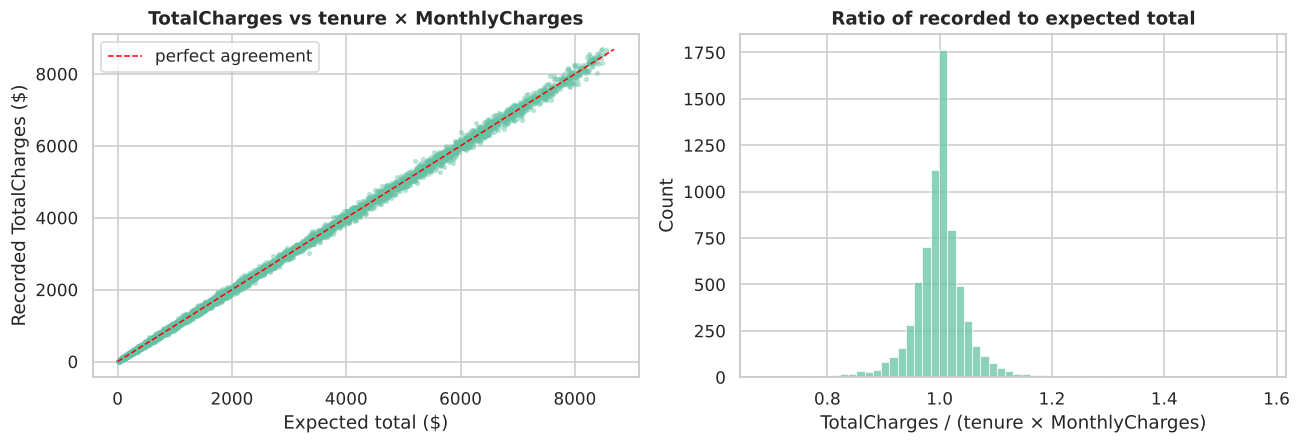

In [15]:
# Visualise the consistency check
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(billed["expected_total"], billed["TotalCharges"], s=6, alpha=0.35)
lim = billed[["expected_total", "TotalCharges"]].max().max()
ax[0].plot([0, lim], [0, lim], "r--", lw=1, label="perfect agreement")
ax[0].set(title="TotalCharges vs tenure × MonthlyCharges",
          xlabel="Expected total ($)", ylabel="Recorded TotalCharges ($)")
ax[0].legend()
sns.histplot(billed["ratio"], bins=60, ax=ax[1])
ax[1].set(title="Ratio of recorded to expected total", xlabel="TotalCharges / (tenure × MonthlyCharges)")
plt.tight_layout(); plt.savefig("figures/noise_consistency_check.png", bbox_inches="tight"); plt.show()

In [16]:
# --- 3) IQR outlier detection on numeric columns -----------------------------
def iqr_outliers(s):
    """Return the lower/upper Tukey fences and the number of points outside them."""
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return lo, hi, int(((s < lo) | (s > hi)).sum())

outlier_table = pd.DataFrame(
    [iqr_outliers(df[c]) for c in num_cols],
    index=num_cols, columns=["lower_fence", "upper_fence", "n_outliers"]).round(2)
outlier_table

,lower_fence,upper_fence,n_outliers
tenure,-60.00,124.00,0
MonthlyCharges,-46.02,171.38,0
TotalCharges,-4683.52,8868.67,0


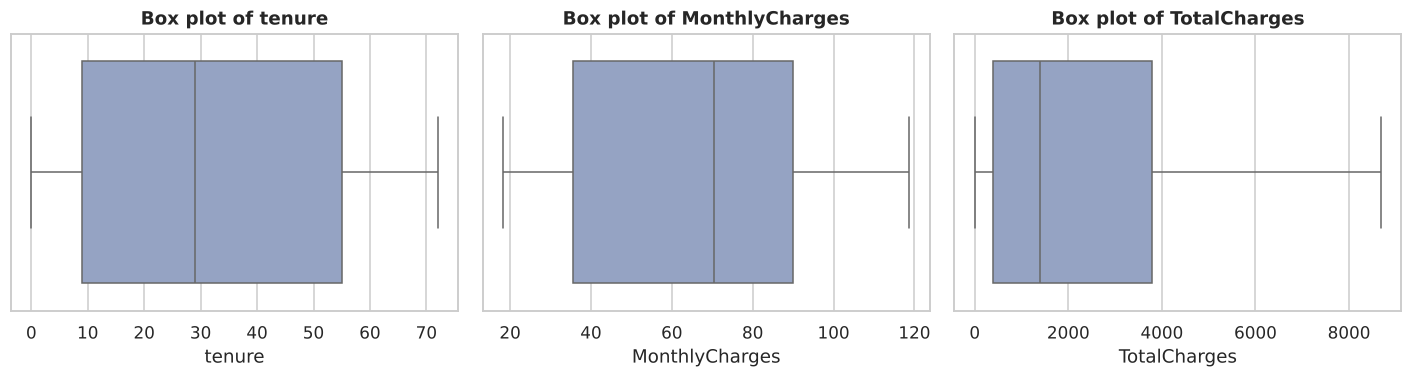

In [17]:
# Box plots make the (absence of) outliers visible
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, num_cols):
    sns.boxplot(x=df[c], ax=ax, color="#8da0cb")
    ax.set_title(f"Box plot of {c}")
plt.tight_layout(); plt.savefig("figures/boxplots_numeric.png", bbox_inches="tight"); plt.show()

**Decision on noisy data:**
- No negative or impossible values were found, and every value is within a plausible business range.
- `TotalCharges` agrees closely with `tenure × MonthlyCharges` (median ratio = 1.00; 98% of customers fall between 0.86 and 1.16).
  Only 2 customers fall outside the 0.5–1.5 band, and only just (maximum 1.57). Both are short-tenure customers, for whom a single
  plan change or one-off charge shifts the ratio a lot, so they are plausible values rather than entry errors and were **kept**.
- The IQR rule finds **no outliers** in any numeric column. `TotalCharges` is strongly right-skewed, but its long tail
  is made up of real long-tenure, high-spend customers, not noise, so the values are **kept unchanged**. For later
  modelling, the skew can be reduced with a log transform or scaling rather than by removing data.

### 3.5 Final cleaned dataset

In [18]:
# --- Add a binary churn flag (1 = churned) for easy rate calculations ---------
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)

# --- Ordered categorical types give sensible ordering in plots and models -----
df["Contract"] = pd.Categorical(df["Contract"], ["Month-to-month", "One year", "Two year"], ordered=True)

# --- Cleaned analysis set: drop the identifier --------------------------------
clean_df = df.drop(columns="customerID")
print("Cleaned shape:", clean_df.shape)
print("Missing values:", int(clean_df.isnull().sum().sum()))

# Save the cleaned data so later deliverables start from the same point
clean_df.to_csv("data/telco_churn_cleaned.csv", index=False)
clean_df.head()

Cleaned shape: (7043, 21)
Missing values: 0


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_flag
0,Female,No,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,No,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (auto),42.30,1840.75,No,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [19]:
# --- Cleaning summary --------------------------------------------------------
summary = pd.DataFrame({
    "Issue": ["TotalCharges stored as text with 11 blanks",
              "SeniorCitizen coded 0/1, others Yes/No",
              "'No internet/phone service' duplicates 'No'",
              "Duplicate records",
              "Noisy values / outliers",
              "customerID has no analytic value"],
    "Action taken": ["Converted to float; imputed 0 (all had tenure = 0)",
                     "Mapped to No/Yes",
                     "Merged into 'No' in 7 columns",
                     "None found by row or ID; profile matches kept",
                     "Range, consistency and IQR checks passed; values kept",
                     "Dropped from the analysis set"]})
summary

,Issue,Action taken
0,TotalCharges stored as text with 11 blanks,Converted to float; imputed 0 (all had tenure ...
1,"SeniorCitizen coded 0/1, others Yes/No",Mapped to No/Yes
2,'No internet/phone service' duplicates 'No',Merged into 'No' in 7 columns
3,Duplicate records,None found by row or ID; profile matches kept
4,Noisy values / outliers,"Range, consistency and IQR checks passed; valu..."
5,customerID has no analytic value,Dropped from the analysis set


## 4. Exploratory Data Analysis

### 4.1 Target variable: how many customers churn?

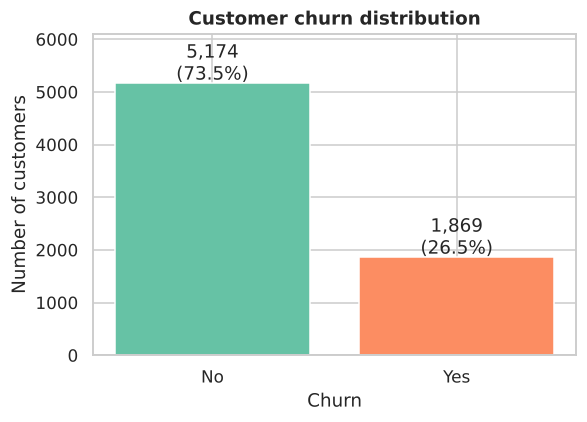

In [20]:
fig, ax = plt.subplots(figsize=(5.5, 4))
counts = clean_df["Churn"].value_counts()
bars = ax.bar(counts.index, counts.values, color=["#66c2a5", "#fc8d62"])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 60, f"{v:,}\n({v / len(clean_df):.1%})", ha="center")
ax.set(title="Customer churn distribution", xlabel="Churn", ylabel="Number of customers", ylim=(0, counts.max() * 1.18))
plt.tight_layout(); plt.savefig("figures/churn_distribution.png", bbox_inches="tight"); plt.show()

About **26.5%** of customers churned. The classes are **imbalanced** (roughly 3:1), so accuracy alone would be misleading for
classification. Deliverable 3 will report F1-score and ROC-AUC and use stratified splits.

### 4.2 Distributions of the numeric features

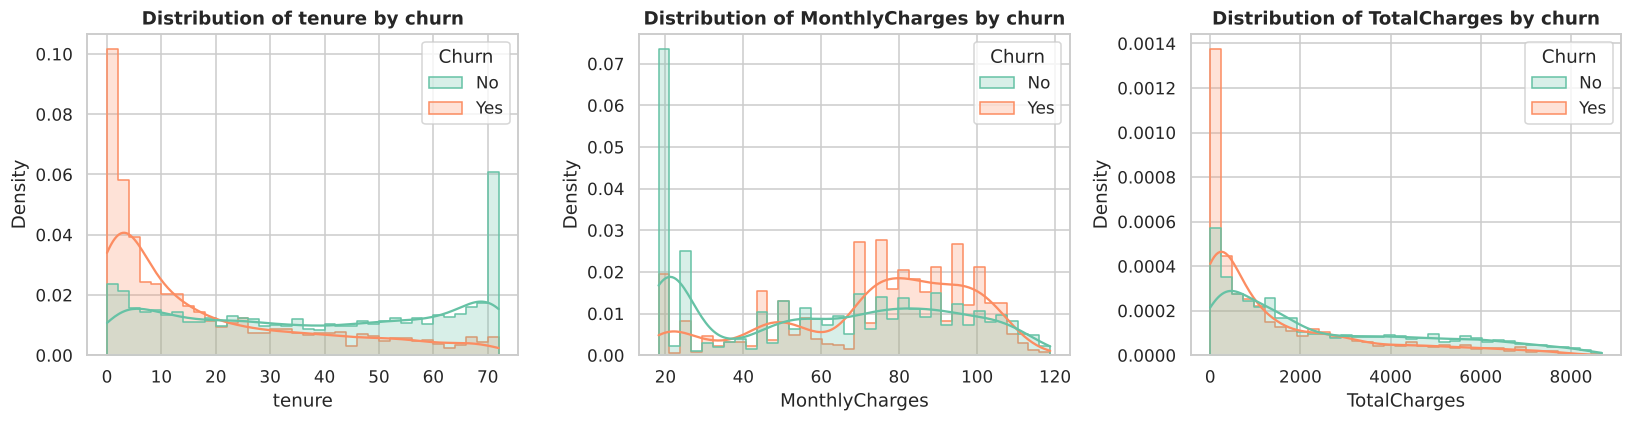

,tenure,MonthlyCharges,TotalCharges
skewness,0.24,-0.221,0.963


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(data=clean_df, x=c, hue="Churn", bins=36, kde=True, ax=ax,
                 element="step", stat="density", common_norm=False)
    ax.set_title(f"Distribution of {c} by churn")
plt.tight_layout(); plt.savefig("figures/numeric_distributions_by_churn.png", bbox_inches="tight"); plt.show()

# Skewness quantifies the asymmetry seen in the histograms
clean_df[num_cols].skew().round(3).to_frame("skewness").T

- **tenure** is U-shaped: many brand-new customers and many customers of about 6 years. Churners are concentrated in the **first months**.
- **MonthlyCharges** peaks at about \$20 (phone-only plans) and spreads up to \$119; churners lean towards **higher monthly bills** (\$70–\$110).
- **TotalCharges** is strongly right-skewed. Churners have lower totals because they leave early, not because they pay less per month.

### 4.3 Churn rate across categorical features

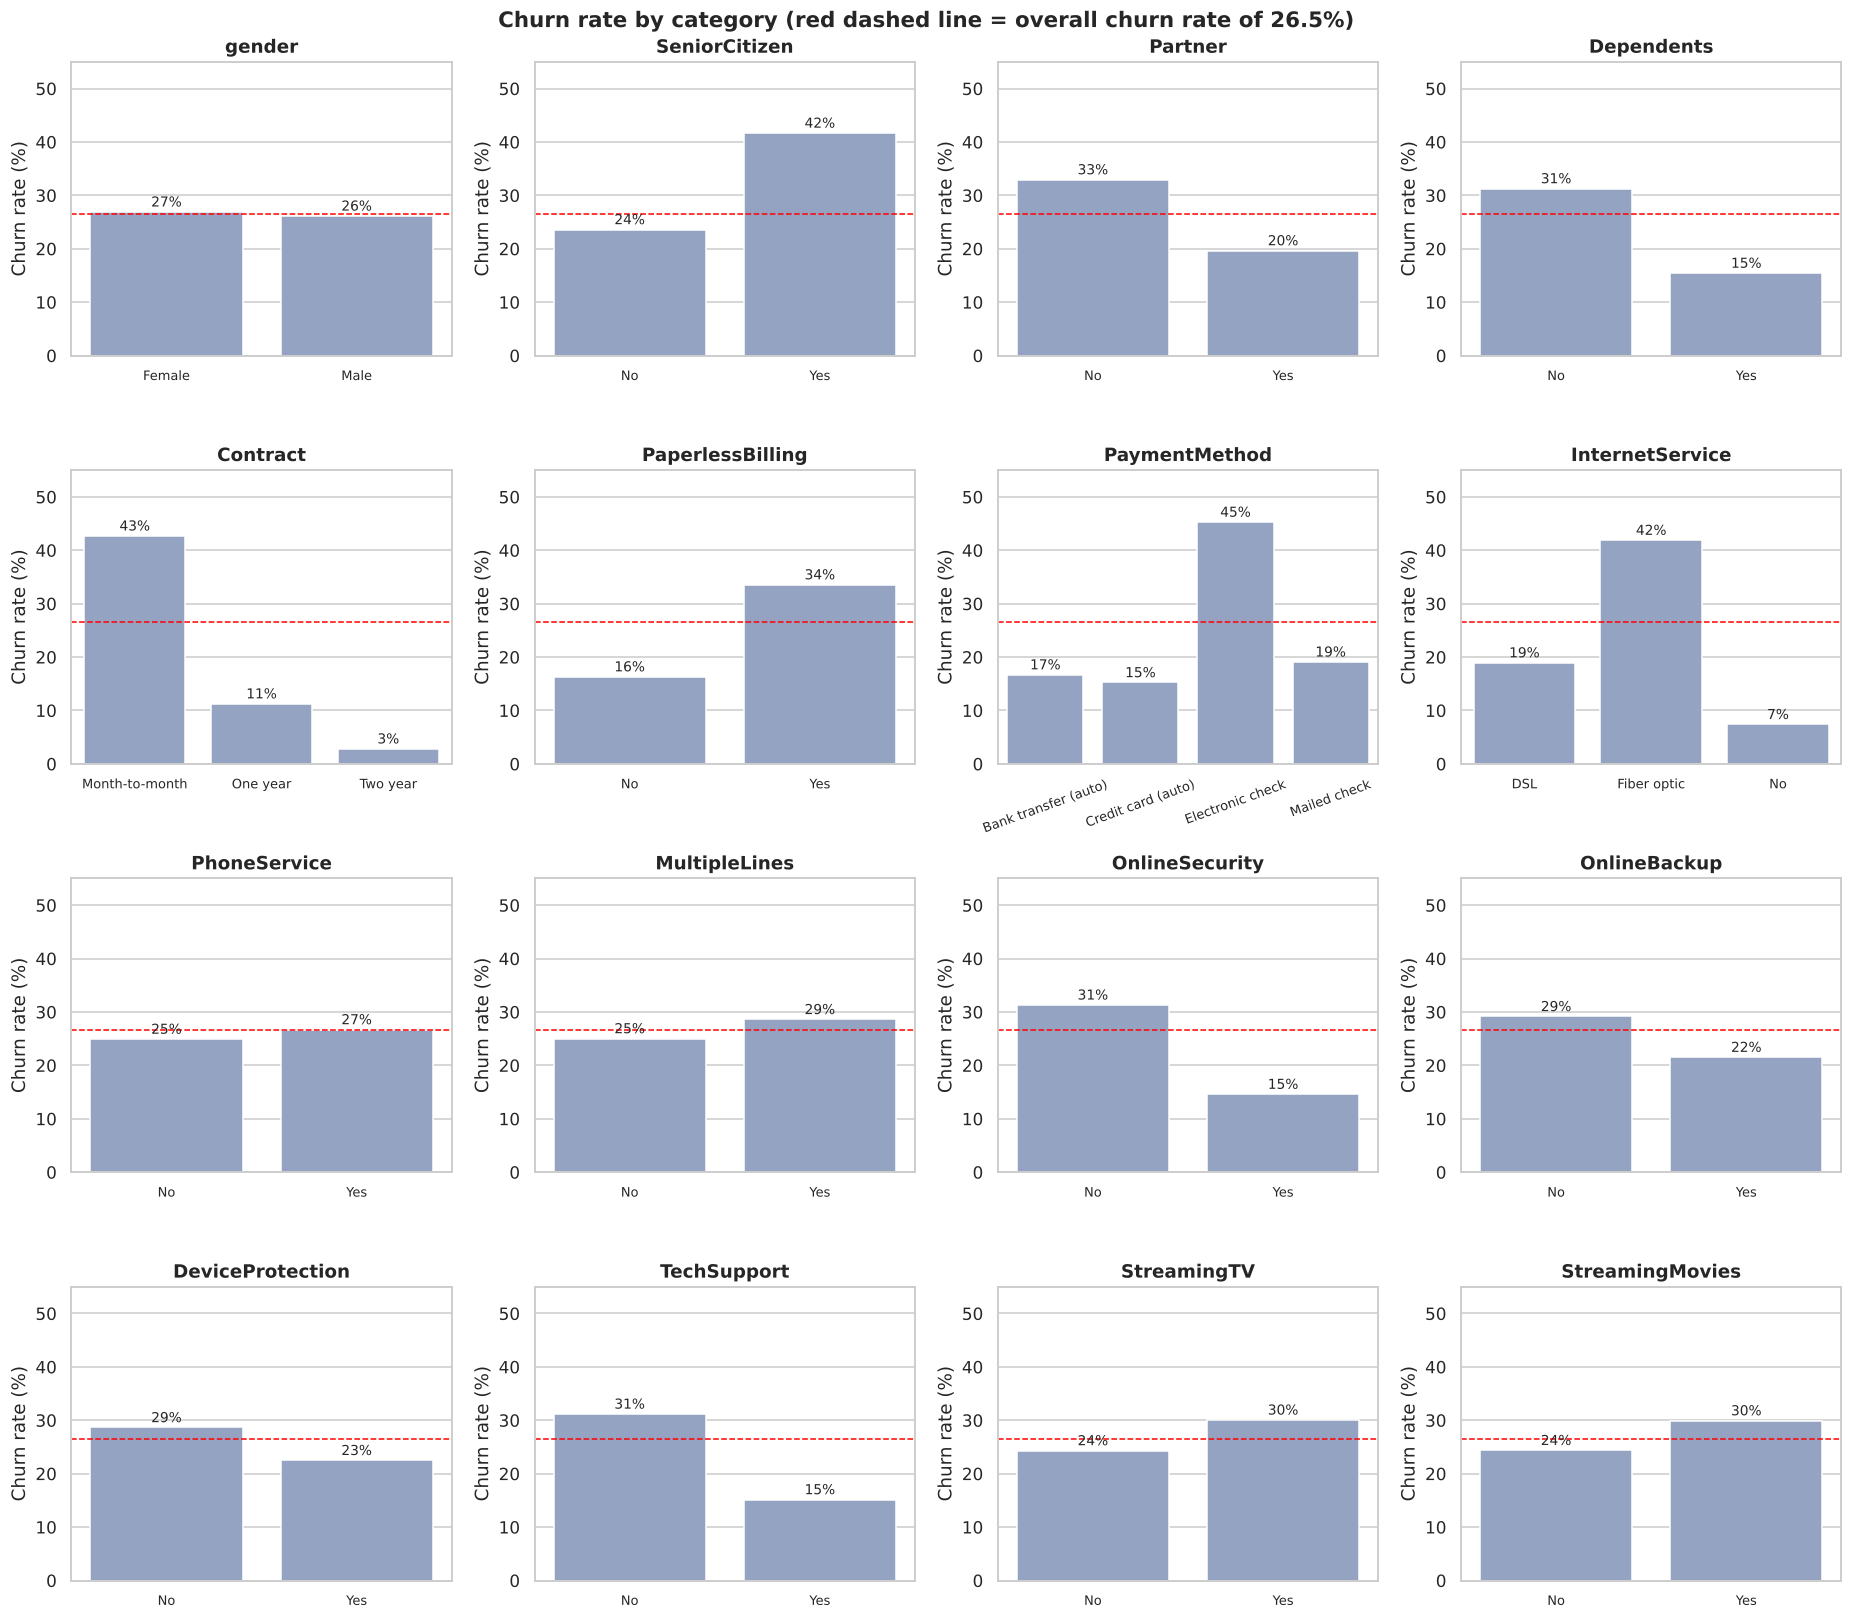

In [22]:
# Churn rate (% churned) for each level of every categorical feature
plot_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "Contract", "PaperlessBilling",
             "PaymentMethod", "InternetService", "PhoneService", "MultipleLines",
             "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
             "StreamingTV", "StreamingMovies"]
overall = clean_df["Churn_flag"].mean()

fig, axes = plt.subplots(4, 4, figsize=(17, 15))
for ax, c in zip(axes.flat, plot_cols):
    rate = clean_df.groupby(c, observed=True)["Churn_flag"].mean().mul(100)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#8da0cb")
    ax.axhline(overall * 100, color="red", ls="--", lw=1)
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set(title=c, xlabel="", ylabel="Churn rate (%)", ylim=(0, 55))
    ax.tick_params(axis="x", rotation=20 if c == "PaymentMethod" else 0, labelsize=8.5)
fig.suptitle("Churn rate by category (red dashed line = overall churn rate of 26.5%)", fontsize=14, weight="bold")
plt.tight_layout(); plt.savefig("figures/churn_rate_by_category.png", bbox_inches="tight"); plt.show()

In [23]:
# --- Rank categorical features by how much the churn rate varies across their levels ---
spread = {c: clean_df.groupby(c, observed=True)["Churn_flag"].mean().agg(lambda s: s.max() - s.min()) * 100
          for c in plot_cols}
pd.Series(spread).sort_values(ascending=False).round(1).to_frame("churn_rate_spread_pct_points").T

,Contract,InternetService,PaymentMethod,SeniorCitizen,PaperlessBilling,OnlineSecurity,TechSupport,Dependents,Partner,OnlineBackup,DeviceProtection,StreamingTV,StreamingMovies,MultipleLines,PhoneService,gender
churn_rate_spread_pct_points,39.9,34.5,30.0,18.1,17.2,16.7,16.0,15.8,13.3,7.6,6.1,5.7,5.6,3.6,1.8,0.8


**Strongest churn drivers among the categorical features:**
- **Contract:** month-to-month customers churn at about **43%**, versus about 11% (one-year) and about 3% (two-year), the largest effect in the data.
- **InternetService:** fiber-optic customers churn at about **42%**, more than double the DSL rate, despite paying for the premium service.
- **PaymentMethod:** electronic-check payers churn at about **45%**; automatic payments are linked to much lower churn.
- **No OnlineSecurity / TechSupport:** about 31–33% churn versus about 15% for those who have them, so support add-ons go with retention.
- **SeniorCitizen, no Partner, no Dependents, PaperlessBilling:** moderately higher churn.
- **gender** and **PhoneService** show almost **no difference**, so they are weak predictors.

### 4.4 Relationships between numeric features and churn

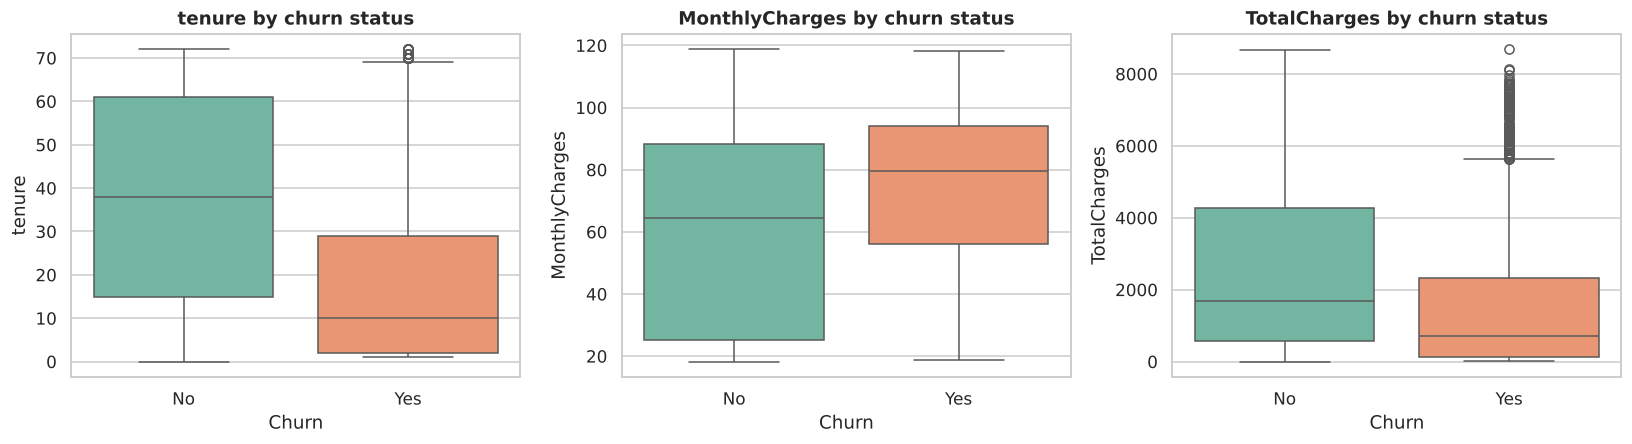

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1679.52
Yes,10.0,79.65,703.55


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=clean_df, x="Churn", y=c, ax=ax, hue="Churn", legend=False)
    ax.set_title(f"{c} by churn status")
plt.tight_layout(); plt.savefig("figures/numeric_boxplots_by_churn.png", bbox_inches="tight"); plt.show()

clean_df.groupby("Churn")[num_cols].median().round(2)

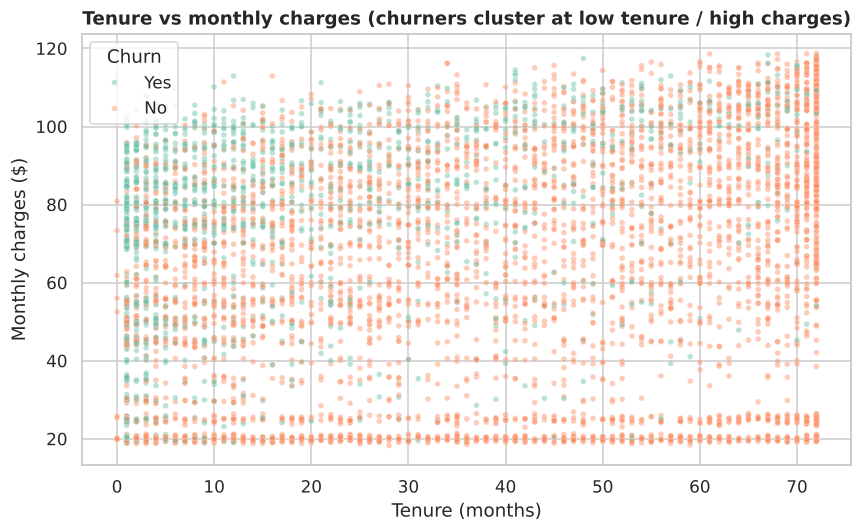

In [25]:
# --- Tenure vs MonthlyCharges scatter, coloured by churn -------------------------
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=clean_df.sample(frac=1, random_state=42), x="tenure", y="MonthlyCharges",
                hue="Churn", alpha=0.45, s=14, ax=ax)
ax.set(title="Tenure vs monthly charges (churners cluster at low tenure / high charges)",
       xlabel="Tenure (months)", ylabel="Monthly charges ($)")
plt.tight_layout(); plt.savefig("figures/tenure_vs_monthly_scatter.png", bbox_inches="tight"); plt.show()

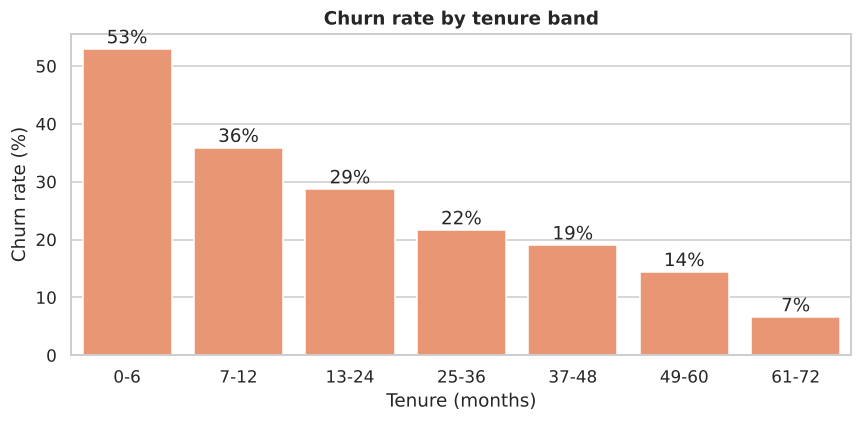

In [26]:
# --- Churn rate by tenure band ---------------------------------------------------
bands = pd.cut(clean_df["tenure"], bins=[-1, 6, 12, 24, 36, 48, 60, 72],
               labels=["0-6", "7-12", "13-24", "25-36", "37-48", "49-60", "61-72"])
tenure_rate = clean_df.groupby(bands, observed=True)["Churn_flag"].mean().mul(100)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=tenure_rate.index, y=tenure_rate.values, ax=ax, color="#fc8d62")
for i, v in enumerate(tenure_rate.values):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
ax.set(title="Churn rate by tenure band", xlabel="Tenure (months)", ylabel="Churn rate (%)")
plt.tight_layout(); plt.savefig("figures/churn_by_tenure_band.png", bbox_inches="tight"); plt.show()

### 4.5 Correlation analysis

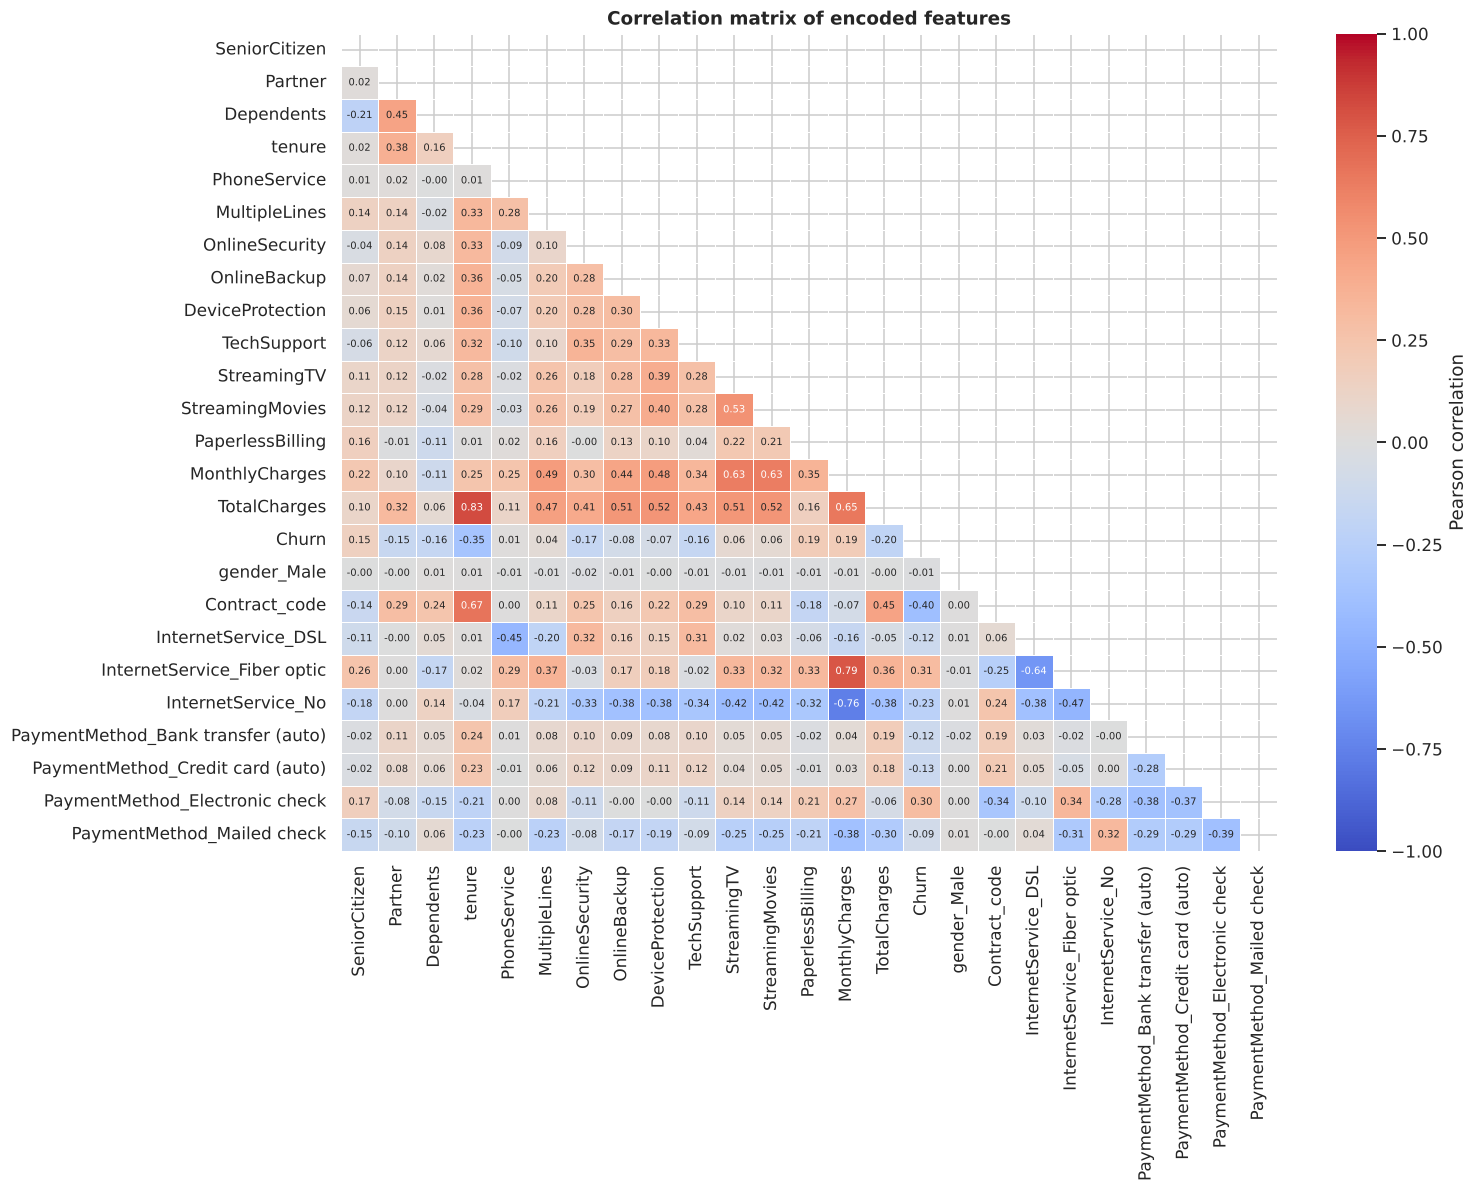

In [27]:
# Encode binary Yes/No columns as 1/0 and one-hot encode multi-level columns so that
# relationships between all features can be measured on one correlation matrix.
corr_df = clean_df.copy()
binary_cols = [c for c in corr_df.columns
               if corr_df[c].dtype in ["object", "string"] and set(corr_df[c].unique()) <= {"Yes", "No"}]
corr_df[binary_cols] = (corr_df[binary_cols] == "Yes").astype(int)
corr_df["gender_Male"] = (corr_df.pop("gender") == "Male").astype(int)
corr_df["Contract_code"] = corr_df.pop("Contract").cat.codes      # 0=M2M, 1=1yr, 2=2yr (ordinal)
corr_df = pd.get_dummies(corr_df.drop(columns="Churn_flag"),
                         columns=["InternetService", "PaymentMethod"], dtype=int)

corr = corr_df.corr()
fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 6.5}, linewidths=.4, ax=ax,
            cbar_kws={"label": "Pearson correlation"})
ax.set_title("Correlation matrix of encoded features")
plt.tight_layout(); plt.savefig("figures/correlation_heatmap.png", bbox_inches="tight"); plt.show()

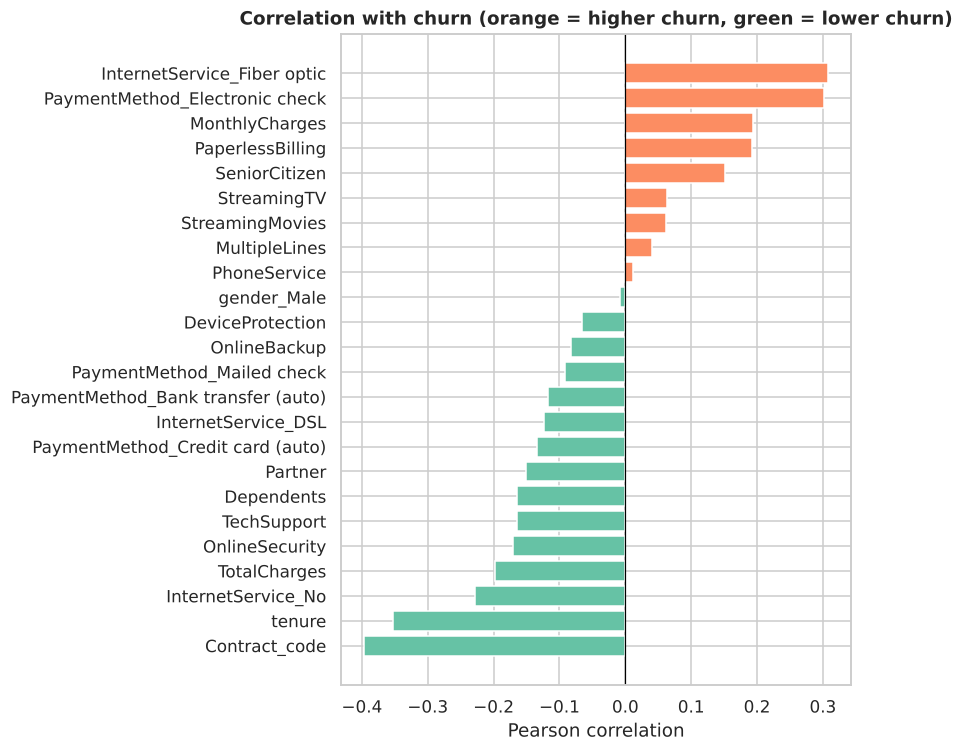

In [28]:
# --- Correlation of each feature with Churn, sorted --------------------------------
churn_corr = corr["Churn"].drop("Churn").sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#66c2a5" if v < 0 else "#fc8d62" for v in churn_corr]
ax.barh(churn_corr.index, churn_corr.values, color=colors)
ax.axvline(0, color="black", lw=.8)
ax.set(title="Correlation with churn (orange = higher churn, green = lower churn)", xlabel="Pearson correlation")
plt.tight_layout(); plt.savefig("figures/correlation_with_churn.png", bbox_inches="tight"); plt.show()

In [29]:
# --- Strongly correlated feature pairs (multicollinearity check) ------------------
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("corr").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs.loc[pairs["corr"].abs() >= 0.6].sort_values("corr", key=abs, ascending=False).round(3)

,feature_1,feature_2,corr
89,tenure,TotalCharges,0.826
344,MonthlyCharges,InternetService_Fiber optic,0.787
345,MonthlyCharges,InternetService_No,-0.764
92,tenure,Contract_code,0.672
339,MonthlyCharges,TotalCharges,0.651
469,InternetService_DSL,InternetService_Fiber optic,-0.641
263,StreamingTV,MonthlyCharges,0.630
288,StreamingMovies,MonthlyCharges,0.627


- **Features most associated with churn:** month-to-month contracts (low `Contract_code`, r ≈ −0.40), short `tenure` (r ≈ −0.35), fiber-optic internet (+0.31), electronic-check payment (+0.30).
- **Multicollinearity:** `TotalCharges` is strongly correlated with `tenure` (r ≈ 0.83) and with `MonthlyCharges` (r ≈ 0.65), because it is essentially their product. `MonthlyCharges` is also highly correlated with fiber-optic service and streaming add-ons. Regression models in Deliverable 2 should use regularisation (Ridge/Lasso) or drop redundant features.

### 4.6 Multivariate view: contract type × internet service

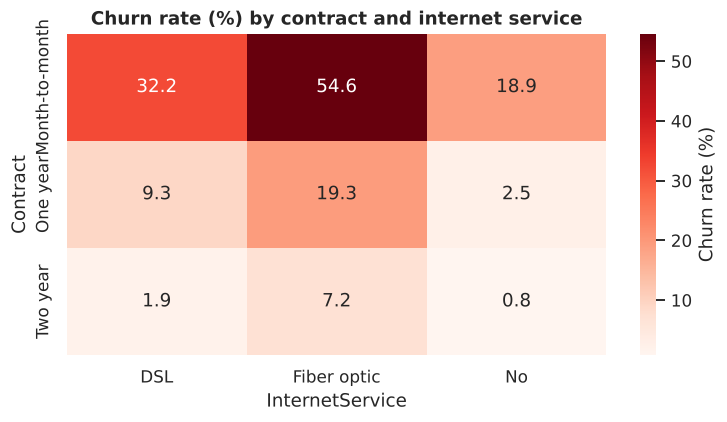

In [30]:
pivot = clean_df.pivot_table(index="Contract", columns="InternetService",
                             values="Churn_flag", aggfunc="mean", observed=True).mul(100)
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate (%) by contract and internet service")
plt.tight_layout(); plt.savefig("figures/contract_internet_heatmap.png", bbox_inches="tight"); plt.show()

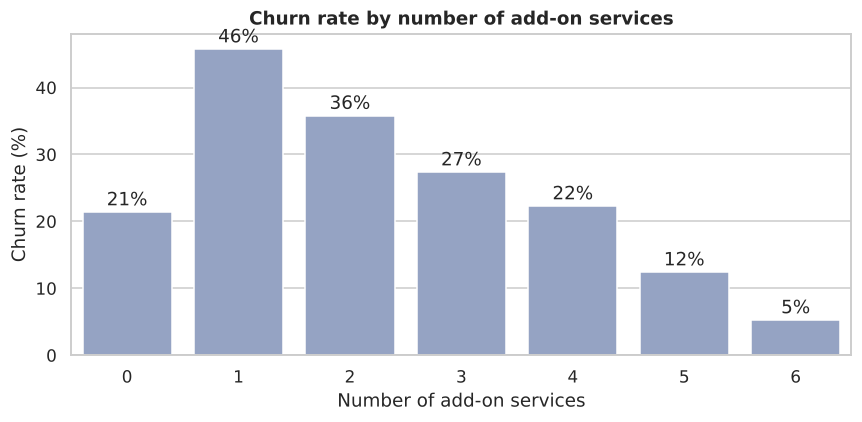

,churn_rate,customers
0,21.4,2219
1,45.8,966
2,35.8,1033
3,27.4,1118
4,22.3,852
5,12.4,571
6,5.3,284


In [31]:
# --- Number of add-on services vs churn (a feature to engineer in Deliverable 2) ---
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
n_addons = (clean_df[addons] == "Yes").sum(axis=1)
addon_rate = clean_df.groupby(n_addons)["Churn_flag"].agg(["mean", "size"])
addon_rate.columns = ["churn_rate", "customers"]

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=addon_rate.index, y=addon_rate["churn_rate"] * 100, ax=ax, color="#8da0cb")
for i, v in enumerate(addon_rate["churn_rate"] * 100):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
ax.set(title="Churn rate by number of add-on services", xlabel="Number of add-on services", ylabel="Churn rate (%)")
plt.tight_layout(); plt.savefig("figures/churn_by_addon_count.png", bbox_inches="tight"); plt.show()
addon_rate.assign(churn_rate=lambda d: (d.churn_rate * 100).round(1))

## 5. Key Insights and How They Guide Future Modelling

### Insights from EDA
1. **Contract type is the strongest churn signal.** Month-to-month customers churn at about 43%, versus about 3% for two-year contracts.
2. **Churn happens early.** About half of customers in their first 6 months churn; the rate falls steadily with tenure.
3. **High monthly bills and fiber-optic service increase churn.** Fiber customers on month-to-month contracts are the highest-risk group (about 55% churn).
4. **Payment friction matters.** Electronic-check users churn at about 45%, versus about 15–17% for automatic payment methods.
5. **Protective add-ons go with loyalty.** Customers with OnlineSecurity or TechSupport churn about half as often. Among internet customers, churn falls steadily as the number of add-ons rises (about 46% with 1 add-on down to about 5% with all 6). Customers with *no* internet service (phone-only) churn least overall (about 7%), which is why the "0 add-ons" group is lower than the "1 add-on" group.
6. **Demographics play a smaller role.** Gender has no effect; seniors and customers without partners or dependents churn somewhat more.
7. **The data quality is good after cleaning.** The only real problem was 11 blank `TotalCharges` values for new customers; there were no outliers or duplicates.

### How these insights guide Deliverables 2–4
| Insight | Planned action |
|---|---|
| `TotalCharges` ≈ `tenure × MonthlyCharges` (high collinearity) | **Regression:** predict `MonthlyCharges` from the service mix; use Ridge/Lasso to handle correlated predictors; log-transform `TotalCharges` if it is used. |
| Churn rate depends on the number of add-ons and on tenure stage | **Feature engineering:** create `num_addons`, tenure bands, `avg_monthly_spend = TotalCharges / tenure`, and an `auto_payment` flag. |
| 26.5% vs 73.5% class imbalance | **Classification:** stratified train/test split; evaluate with F1, ROC-AUC and confusion matrices; consider class weights. |
| Features differ in scale (tenure 0–72, TotalCharges 0–8,700) | **k-NN / SVM / K-Means:** standardise numeric features first. |
| Clear customer profiles (new + fiber + month-to-month vs long-term + two-year) | **Clustering:** K-Means on tenure, charges and service usage to find segments. |
| Many Yes/No service columns | **Association rules:** treat services and churn as items; use Apriori to find rules such as {Month-to-month, Fiber optic, No TechSupport} → {Churn = Yes}. |
| `gender`, `PhoneService` show no effect | Candidates for removal during feature selection. |